# Dự đoán nhiệt độ trong nhà bằng LSTM

Notebook đọc dữ liệu cảm biến từ ESP32, gộp mẫu theo 3 phút, tạo cửa sổ trượt và huấn luyện mô hình LSTM để dự đoán nhiệt độ sau 30 phút. Kết quả được so sánh với baseline “giữ nguyên nhiệt độ hiện tại”.

**Các bước:** đọc dữ liệu → gộp mẫu → đặc trưng thời gian → chia train/test theo thời gian → chuẩn hóa (fit trên train) → tạo cửa sổ trượt → huấn luyện LSTM → đánh giá và vẽ biểu đồ → lưu mô hình.

> Chạy notebook từ thư mục `notebooks/`. Chọn **Restart and Run All** để đảm bảo kết quả không phụ thuộc thứ tự chạy cell.

## 1. Cấu hình

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.random.set_seed(42)
np.random.seed(42)

CSV_PATH = '/content/drive/MyDrive/arduino-dht11/data/sensor_data.csv'
RESAMPLE = '3min'
WINDOW = 30          # 30 mẫu lịch sử = 90 phút
HORIZON = 10         # dự báo 10 mẫu sau = 30 phút
TRAIN_RATIO = 0.7    # 70% đầu cho train, 30% cuối cho test
VAL_RATIO = 0.15     # 15% cuối của phần train làm validation

# Cột mục tiêu phải đứng đầu danh sách
FEATURES = ['temperature', 'humidity', 'co2', 'voc', 'pm25']
TARGET = 'temperature'
assert FEATURES[0] == TARGET

DOCS_DIR = '../docs'
MODEL_DIR = '../models'
os.makedirs(DOCS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 2. Đọc và làm sạch dữ liệu

In [14]:
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv(CSV_PATH)

# Chuyển timestamp sang múi giờ Việt Nam để tính đặc trưng giờ trong ngày
df['dt'] = pd.to_datetime(df['timestamp'], utc=True).dt.tz_convert('Asia/Bangkok')
df = df.sort_values('dt').set_index('dt')

# Gộp trung bình theo khoảng cố định, bỏ khoảng trống
df = df[FEATURES].resample(RESAMPLE).mean().dropna()

print('Số mẫu sau khi gộp:', len(df))
print('Khoảng thời gian:', df.index.min(), '->', df.index.max())
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Số mẫu sau khi gộp: 3801
Khoảng thời gian: 2025-11-25 13:30:00+07:00 -> 2025-12-03 12:09:00+07:00


,temperature,humidity,co2,voc,pm25
dt,,,,,
2025-11-25 13:30:00+07:00,33.766667,49.333333,612.000000,32.000000,11.000000
2025-11-25 13:33:00+07:00,33.300000,51.666667,651.000000,38.000000,6.666667
2025-11-25 13:36:00+07:00,33.300000,53.000000,664.000000,39.666667,4.333333
2025-11-25 13:39:00+07:00,33.300000,52.666667,676.000000,41.333333,1.333333
2025-11-25 13:42:00+07:00,33.300000,51.666667,660.666667,39.333333,1.333333


## 3. Đặc trưng thời gian

Mã hóa giờ trong ngày bằng sin/cos để 23:59 và 00:01 được coi là gần nhau.

In [15]:
seconds = np.asarray(df.index.hour * 3600 + df.index.minute * 60 + df.index.second)
df['day_sin'] = np.sin(2 * np.pi * seconds / 86400)
df['day_cos'] = np.cos(2 * np.pi * seconds / 86400)

FEATURES_ALL = FEATURES + ['day_sin', 'day_cos']
data = df[FEATURES_ALL].values
N_FEATURES = len(FEATURES_ALL)
print('Số đặc trưng đầu vào:', N_FEATURES)

Số đặc trưng đầu vào: 7


## 4. Chia train/test theo thời gian và chuẩn hóa

Scaler chỉ fit trên phần train để tránh rò rỉ thông tin từ tập test.

In [16]:
n = len(data)
n_train = int(n * TRAIN_RATIO)

scaler = StandardScaler().fit(data[:n_train])
scaled = scaler.transform(data)

def inv_temp(values):
    # Đưa nhiệt độ đã chuẩn hóa về đơn vị °C
    tmp = np.zeros((len(values), N_FEATURES))
    tmp[:, 0] = values
    return scaler.inverse_transform(tmp)[:, 0]

## 5. Tạo cửa sổ trượt

- Đầu vào: `WINDOW` mẫu liên tiếp.
- Nhãn: nhiệt độ sau `HORIZON` mẫu tính từ mẫu cuối của cửa sổ.

Cửa sổ có nhãn nằm trong phần train thuộc tập train. Cửa sổ có đầu vào nằm trong phần test thuộc tập test. Cửa sổ vắt qua ranh giới bị loại bỏ.

In [17]:
n_windows = n - WINDOW - HORIZON + 1
X_all = np.stack([scaled[i:i + WINDOW] for i in range(n_windows)])
y_all = np.array([scaled[i + WINDOW + HORIZON - 1, 0] for i in range(n_windows)])

starts = np.arange(n_windows)
targets = starts + WINDOW + HORIZON - 1

train_mask = targets < n_train
test_mask = starts >= n_train

X_train_full, y_train_full = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

# Validation là đoạn cuối của phần train, không xáo trộn
n_val = int(len(X_train_full) * VAL_RATIO)
X_train, y_train = X_train_full[:-n_val], y_train_full[:-n_val]
X_val, y_val = X_train_full[-n_val:], y_train_full[-n_val:]

print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)

Train: (2228, 30, 7) | Val: (393, 30, 7) | Test: (1102, 30, 7)


## 6. Xây dựng mô hình LSTM

In [18]:
model = models.Sequential([
    layers.Input(shape=(WINDOW, N_FEATURES)),
    layers.LSTM(64, return_sequences=True),
    layers.LSTM(32),
    layers.Dense(32, activation='relu'),
    layers.Dense(1),
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,937 (124.75 KB)

 Trainable params: 31,937 (124.75 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Huấn luyện

In [19]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.3931 - mae: 0.4048 - val_loss: 0.1419 - val_mae: 0.3025
Epoch 2/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1389 - mae: 0.2950 - val_loss: 0.1407 - val_mae: 0.3001
Epoch 3/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1326 - mae: 0.2883 - val_loss: 0.1406 - val_mae: 0.2987
Epoch 4/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1301 - mae: 0.2846 - val_loss: 0.1404 - val_mae: 0.2983
Epoch 5/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1281 - mae: 0.2814 - val_loss: 0.1403 - val_mae: 0.2980
Epoch 6/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.1269 - mae: 0.2791 - val_loss: 0.1404 - val_mae: 0.2982
Epoch 7/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.1260 - mae: 0.2774 - val_loss: 0.1403 - val_mae: 0.2980
Epoch 8/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.1255 - mae: 0.2765 - val_loss: 0.1409 - val_mae: 0.2988
Epoch 9/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - los

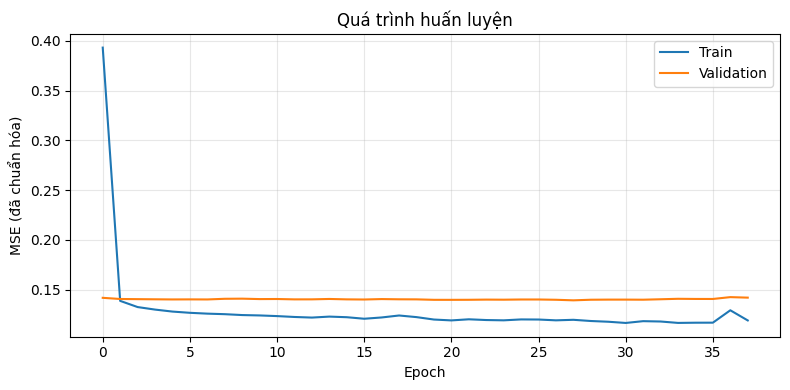

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.history['loss'], label='Train')
ax.plot(history.history['val_loss'], label='Validation')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE (đã chuẩn hóa)')
ax.set_title('Quá trình huấn luyện')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(DOCS_DIR, 'training_loss.png'), dpi=150)
plt.show()

## 8. Đánh giá trên tập test

Sai số được tính trên thang °C, không phải trên dữ liệu đã chuẩn hóa.

In [21]:
y_true = inv_temp(y_test)
y_lstm = inv_temp(model.predict(X_test, verbose=0).ravel())
y_base = inv_temp(X_test[:, -1, 0])   # baseline: nhiệt độ hiện tại

def mae_rmse(y, p):
    return mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p))

mae_b, rmse_b = mae_rmse(y_true, y_base)
mae_l, rmse_l = mae_rmse(y_true, y_lstm)

print('Mô hình'.ljust(12), '| MAE (°C)'.ljust(12), '| RMSE (°C)')
print('-' * 40)
print('Baseline'.ljust(12), '|', f'{mae_b:.4f}'.ljust(10), '|', f'{rmse_b:.4f}')
print('LSTM'.ljust(12), '|', f'{mae_l:.4f}'.ljust(10), '|', f'{rmse_l:.4f}')
print()
print(f'LSTM giảm MAE {(mae_b - mae_l) / mae_b * 100:.1f}%')
print(f'LSTM giảm RMSE {(rmse_b - rmse_l) / rmse_b * 100:.1f}%')

Mô hình      | MAE (°C)   | RMSE (°C)
----------------------------------------
Baseline     | 0.1889     | 0.2391
LSTM         | 0.1362     | 0.1739

LSTM giảm MAE 27.9%
LSTM giảm RMSE 27.3%


## 9. Biểu đồ dự báo so với thực tế

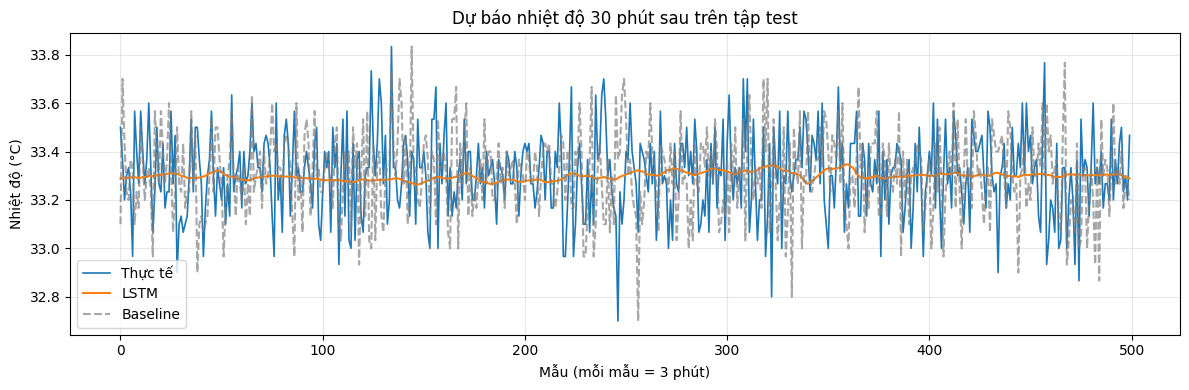

In [22]:
n_plot = min(500, len(y_true))   # khoảng 25 giờ với mẫu 3 phút

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_true[:n_plot], label='Thực tế', color='tab:blue', lw=1.2)
ax.plot(y_lstm[:n_plot], label='LSTM', color='tab:orange', lw=1.5)
ax.plot(y_base[:n_plot], label='Baseline', color='gray', ls='--', alpha=0.7)
ax.set_xlabel('Mẫu (mỗi mẫu = 3 phút)')
ax.set_ylabel('Nhiệt độ (°C)')
ax.set_title('Dự báo nhiệt độ 30 phút sau trên tập test')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(DOCS_DIR, 'forecast_vs_actual.png'), dpi=150)
plt.show()

## 10. Biểu đồ so sánh sai số

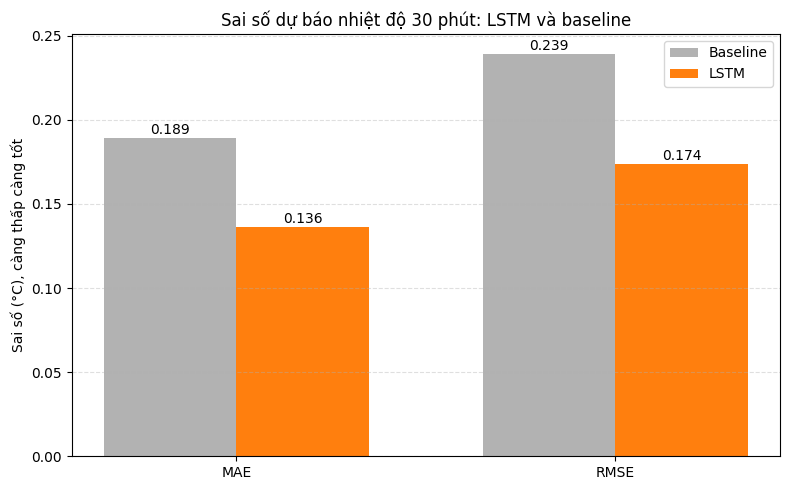

In [23]:
x = np.arange(2)
w = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w / 2, [mae_b, rmse_b], w, label='Baseline', color='gray', alpha=0.6)
b2 = ax.bar(x + w / 2, [mae_l, rmse_l], w, label='LSTM', color='tab:orange')

for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f'{bar.get_height():.3f}',
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points', ha='center')

ax.set_xticks(x, ['MAE', 'RMSE'])
ax.set_ylabel('Sai số (°C), càng thấp càng tốt')
ax.set_title('Sai số dự báo nhiệt độ 30 phút: LSTM và baseline')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
fig.savefig(os.path.join(DOCS_DIR, 'metrics.png'), dpi=150)
plt.show()

## 11. Lưu mô hình

In [24]:
model.save(os.path.join(MODEL_DIR, 'lstm_temperature.keras'))
print('Đã lưu mô hình vào', MODEL_DIR)

Đã lưu mô hình vào ../models


In [25]:
import os

readme_content = f"""# Dự đoán nhiệt độ trong nhà bằng LSTM

Dự án sử dụng mô hình tuần tự LSTM để dự báo nhiệt độ phòng sau 30 phút dựa trên chuỗi lịch sử từ cảm biến (ESP32).

## 1. Cấu hình thực nghiệm
- **Khoảng thời gian gộp mẫu (Resample):** {RESAMPLE}
- **Cửa sổ lịch sử (Window):** {WINDOW} mẫu ({WINDOW * 3:.0f} phút)
- **Thời gian dự báo trước (Horizon):** {HORIZON} mẫu ({HORIZON * 3:.0f} phút)
- **Đặc trưng đầu vào:** {', '.join(FEATURES_ALL)}
- **Tỉ lệ phân chia dữ liệu:** Train: {TRAIN_RATIO*100:.0f}% | Val: {VAL_RATIO*100:.0f}% (phần cuối của Train) | Test: {100 - TRAIN_RATIO*100:.0f}%

## 2. Kết quả đánh giá trên tập Test

Sai số đo bằng đơn vị độ C (°C) sau khi khôi phục chuẩn hóa:

| Mô hình | MAE (°C) | RMSE (°C) |
| :--- | :---: | :---: |
| **Baseline (Giữ nguyên hiện tại)** | {mae_b:.4f} | {rmse_b:.4f} |
| **LSTM** | {mae_l:.4f} | {rmse_l:.4f} |

### Cải thiện hiệu năng:
- **Mức giảm MAE:** {((mae_b - mae_l) / mae_b * 100):.2f}%
- **Mức giảm RMSE:** {((rmse_b - rmse_l) / rmse_b * 100):.2f}%

## 3. Biểu đồ đầu ra
Các biểu đồ kết quả được lưu tại thư mục `{DOCS_DIR}/`:
- `training_loss.png`: Lịch sử lỗi tập Train và Validation qua các epoch.
- `forecast_vs_actual.png`: So sánh giá trị dự báo từ LSTM, Baseline với thực tế.
- `metrics.png`: Biểu đồ cột trực quan so sánh MAE và RMSE.
"""

readme_path = os.path.join(DOCS_DIR, 'README.md')
with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme_content)

print(f"Đã xuất file Markdown thành công tại: {readme_path}")


Đã xuất file Markdown thành công tại: ../docs/README.md
